# Model comparison

Compares training fixes across all tracks using the shared `run_experiment` pipeline. Decisions here use training and validation data only. The test split stays locked until the final comparison (`evaluate_test=True`).

In [1]:
from pathlib import Path
import sys

import pandas as pd

# notebook is in training/benchmarking/notebooks, parents[1] points to training/
sys.path.insert(0, str(Path.cwd().parents[1]))

from benchmarking.data import TRACKS
from benchmarking.diagnostics import overfit_check
from benchmarking.experiment import ExperimentConfig, run_experiment
from benchmarking.fit_check import plot_experiment_training_fit
from benchmarking.metrics import summarize_seeds

RESULTS_DIR = Path.cwd().parent / "results"
RESULTS_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:.4f}".format)

## Phase 1a: can the models memorize a small training set?

Each model trains on 100 windows and is scored on those same windows, with the current unscaled inputs. 100 windows at 20 epochs is only 60 weight updates, so 1,000 epochs is included too. That's about 4,000 updates, similar to a full 20-epoch run on the no-news tracks.

- **R² near 1:** the setup can learn, so the full-data problem is weak signal or training settings.
- **R² far from 1, even at 1,000 epochs:** the setup itself is getting in the way.

In [2]:
overfit = pd.concat([overfit_check(track) for track in TRACKS], ignore_index=True)
overfit.to_csv(RESULTS_DIR / "phase1_overfit.csv", index=False)

overfit_summary = (
    overfit.assign(epochs=overfit["epochs"].astype("Int64").astype("string").fillna("control"))
    .groupby(["track", "model", "epochs"], sort=False)[["r2", "correlation", "spread_ratio"]]
    .agg(["mean", "min", "max"])
)
overfit_summary

r2                  correlation               spread_ratio              
                                                    mean      min     max        mean    min    max         mean    min    max
track                            model   epochs                                                                               
no_news_no_feature_engineering   RNN     20      -3.6675  -5.0017 -2.2398      0.0504 0.0066 0.1028       1.9411 1.5381 2.3394
                                         1000     0.9114   0.7511  0.9938      0.9781 0.9426 0.9971       1.0125 0.9784 1.0794
                                 LSTM    20       0.0209  -0.1821  0.1338      0.2502 0.0217 0.3951       0.4416 0.3552 0.5295
                                         1000     0.7604   0.6843  0.8990      0.9026 0.8673 0.9500       0.8968 0.8559 0.9189
                                 XGBoost control  0.9997   0.9997  0.9997      1.0000 1.0000 1.0000       0.9864 0.9864 0.9864
no_news_with_feature_engineering RNN     20      -4.4731 -10.3036 -1.3028      0.1244 0.0370 0.1739       2.0291 1.3147 3.2465
                                         1000     0.9773   0.9464  0.9985      0.9891 0.9737 0.9993       0.9723 0.9322 0.9934
                                 LSTM    20       0.0230  -0.1097  0.1092      0.2513 0.0943 0.3512       0.4405 0.4158 0.4690
                                         1000     0.8064   0.5826  0.9317      0.9351 0.8808 0.9668       0.8799 0.8259 0.9131
                                 XGBoost control  0.9998   0.9998  0.9998      1.0000 1.0000 1.0000       0.9871 0.9871 0.9871
news_with_feature_engineering    RNN     20      -2.8862  -6.1725 -0.5274      0.2082 0.0920 0.3907       1.7805 1.2153 2.5779
                                         1000     0.9998   0.9995  1.0000      0.9999 0.9998 1.0000       0.9983 0.9957 0.9998
                                 LSTM    20       0.1603   0.0693  0.2086      0.4054 0.3059 0.4582       0.4519 0.4427 0.4569
                                         1000     0.9977   0.9957  0.9997      0.9989 0.9979 0.9999       0.9939 0.9901 0.9979
                                 XGBoost control  0.9999   0.9999  0.9999      1.0000 1.0000 1.0000       0.9909 0.9909 0.9909

## Phase 1b: full training across 5 seeds

The notebook setups on full data, 1-day horizon. A real improvement should beat the baseline on validation across most seeds and be larger than the spread between seeds.

In [3]:
SEEDS = (42, 43, 44, 45, 46)

results = {
    track: run_experiment(ExperimentConfig(track=track, horizons=(1,), seeds=SEEDS))
    for track in TRACKS
}
metrics = pd.concat([result["metrics"] for result in results.values()], ignore_index=True)
metrics.to_csv(RESULTS_DIR / "phase1_seed_metrics.csv", index=False)

summary = summarize_seeds(metrics)
summary.to_csv(RESULTS_DIR / "phase1_seed_summary.csv", index=False)
summary.drop(columns=["horizon", "seeds"])

,track,model,split,r2_mean,r2_std,correlation_mean,correlation_std,spread_ratio_mean,spread_ratio_std,directional_accuracy_mean,directional_accuracy_std,always_up_accuracy,share_beating_baseline
0,no_news_no_feature_engineering,RNN,train,-0.0531,0.0407,0.1031,0.0194,0.3360,0.0596,0.5175,0.0116,0.5087,0.0000
1,no_news_no_feature_engineering,RNN,validation,-0.1436,0.0520,0.0035,0.0387,0.3707,0.0552,0.5017,0.0156,0.5300,0.0000
2,no_news_no_feature_engineering,LSTM,train,-0.0072,0.0123,0.0640,0.0238,0.1145,0.0548,0.5056,0.0082,0.5087,0.4000
3,no_news_no_feature_engineering,LSTM,validation,-0.0262,0.0227,0.0182,0.0387,0.1277,0.0572,0.4986,0.0142,0.5300,0.2000
4,no_news_no_feature_engineering,XGBoost,train,0.2594,0.0022,0.6375,0.0028,0.2542,0.0022,0.6009,0.0048,0.5087,1.0000
5,no_news_no_feature_engineering,XGBoost,validation,-0.0225,0.0034,-0.0346,0.0113,0.1172,0.0032,0.4992,0.0098,0.5300,0.0000
6,no_news_with_feature_engineering,RNN,train,-0.1006,0.0535,0.1200,0.0258,0.4096,0.0872,0.5145,0.0126,0.5094,0.0000
7,no_news_with_feature_engineering,RNN,validation,-0.2323,0.0989,0.0165,0.0194,0.4541,0.1067,0.5077,0.0167,0.5262,0.0000
8,no_news_with_feature_engineering,LSTM,train,-0.0107,0.0348,0.0847,0.0389,0.1352,0.1108,0.5109,0.0079,0.5094,0.6000
9,no_news_with_feature_engineering,LSTM,validation,-0.0338,0.0517,0.0189,0.0221,0.1454,0.1252,0.5120,0.0162,0.5262,0.0000


### Training fit, first seed

no_news_no_feature_engineering


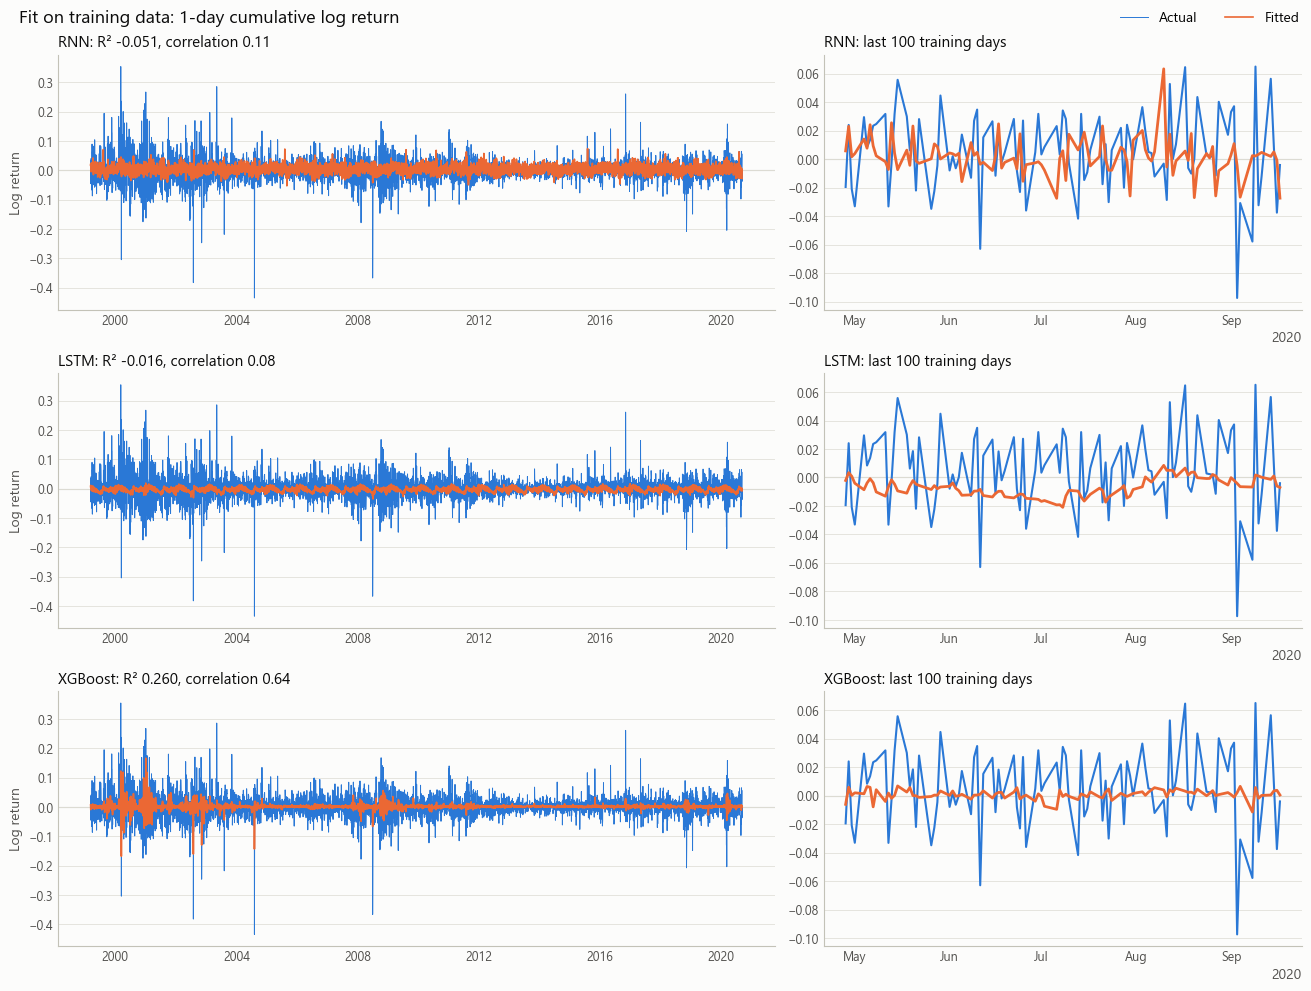

no_news_with_feature_engineering


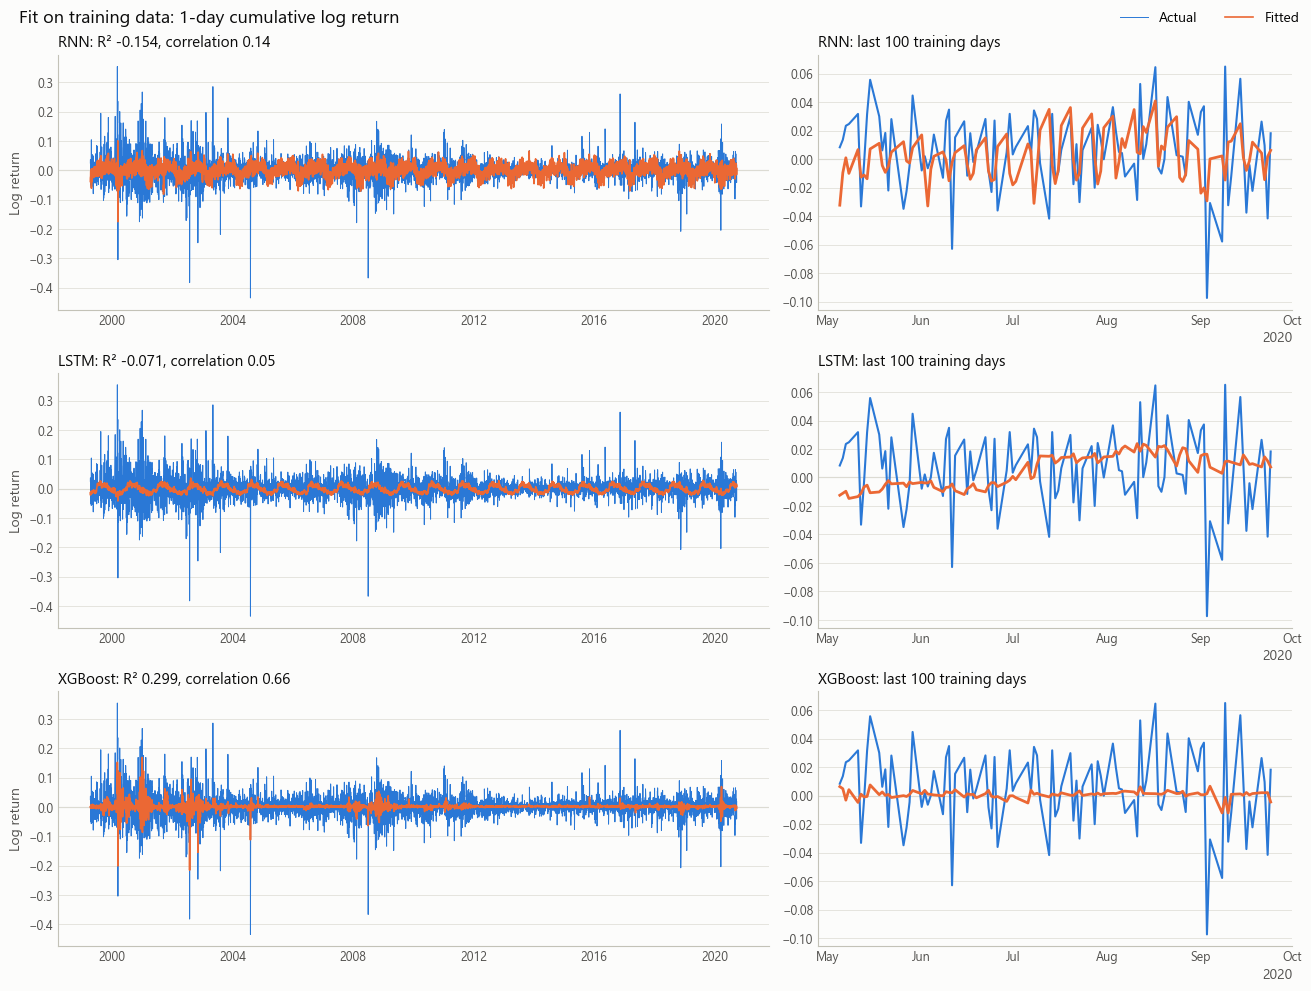

news_with_feature_engineering


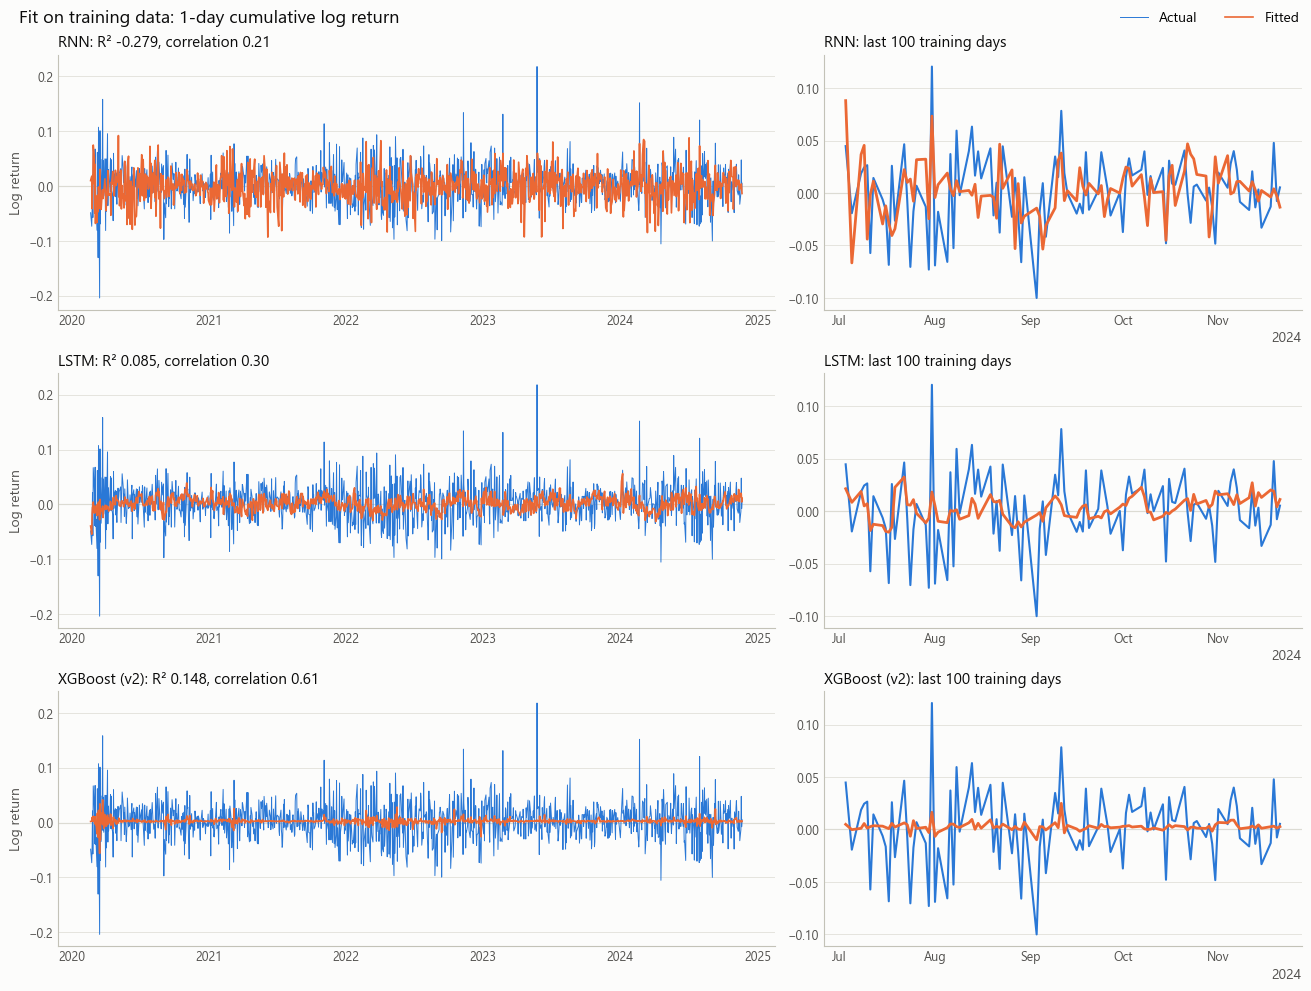

In [4]:
for track, result in results.items():
    print(track)
    plot_experiment_training_fit(result)

## Phase 1 results at a glance

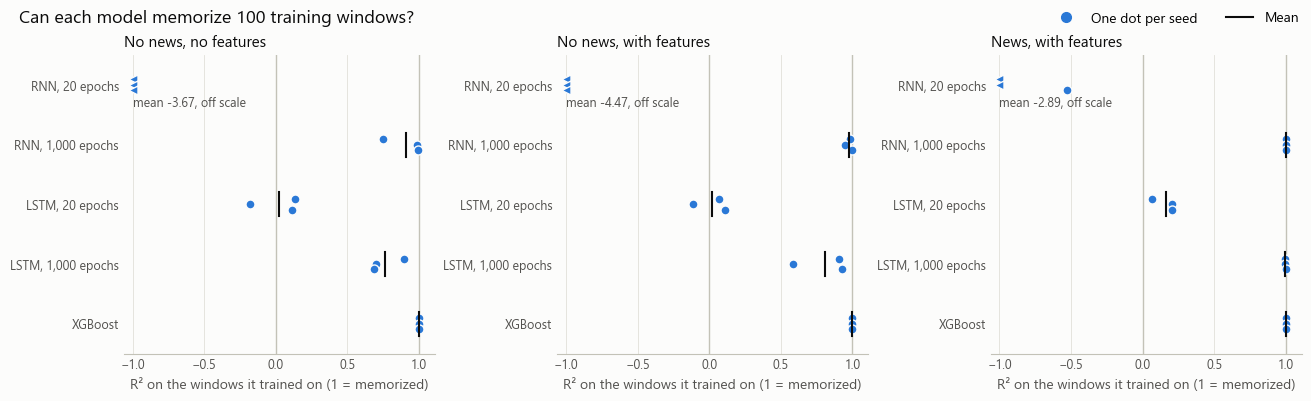

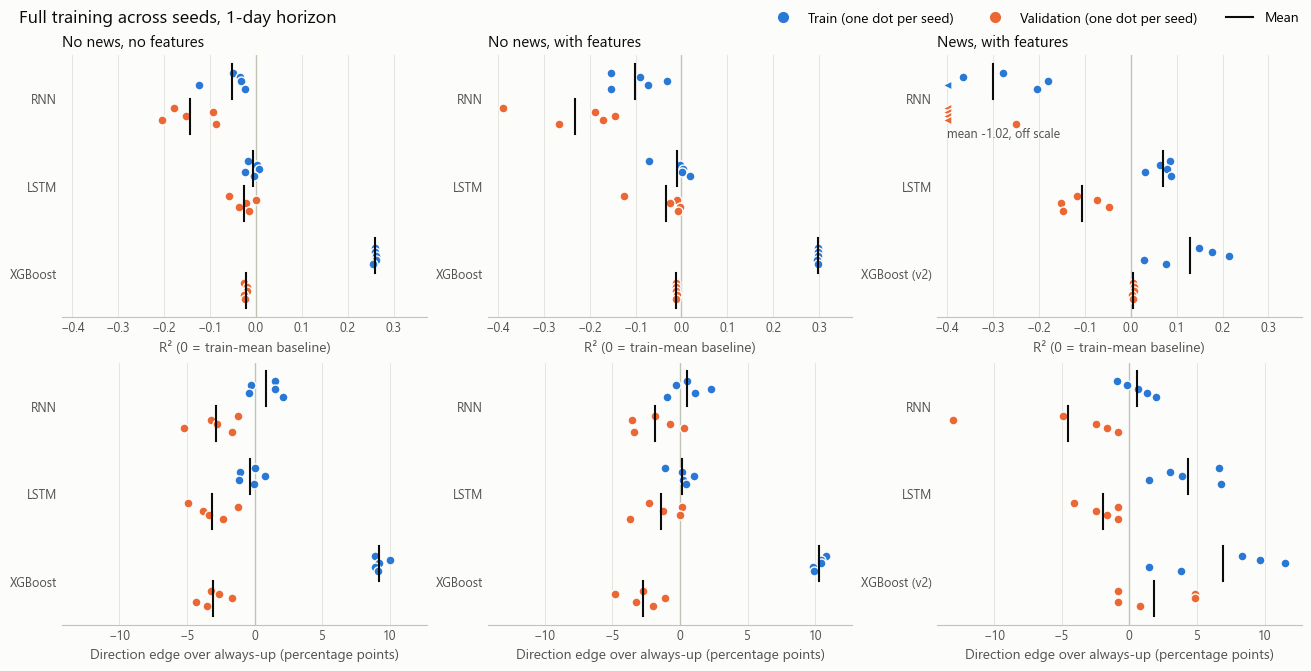

In [5]:
# Reads the saved results, so this cell doesn't retrain anything.
from benchmarking.result_plots import plot_overfit_results, plot_seed_results

plot_overfit_results(pd.read_csv(RESULTS_DIR / "phase1_overfit.csv"))
plot_seed_results(pd.read_csv(RESULTS_DIR / "phase1_seed_metrics.csv"))